# 04 - Live win probability (second innings / the chase)

**What this notebook predicts.** At the end of every over of the chase, the probability that the **chasing team wins**
(1 = chasing team wins, 0 = it loses). Example: "after 15 overs, 128/4 chasing 171 -> 41% to win".

**Why it is a better problem than score prediction.** In notebook 03 the first innings had no target, so the final score
stayed uncertain until the very end. A chase has a target, so the question becomes concrete: *do the runs needed fit in the
balls left, given the wickets in hand?* The state of the match carries a lot of information.

**Same discipline as notebook 03**
* One row per (match, end of over k), k = 1..19, only while the match is still undecided.
* Features use only balls already bowled, the target (known when the chase starts) and pre-match context from earlier dates.
* Season-based rolling-origin validation (folds 2021-25); **the 2026 holdout is evaluated once, at the end**.
* Every comparison is paired by match with a bootstrap confidence interval.

## How to read the metrics (all lower is better except accuracy / AUC)
| Metric | Plain meaning | Reference points |
|---|---|---|
| **Log loss** | Penalises confident wrong answers heavily. The main score. | 0.693 = always saying 50% (no information) |
| **Brier score** | Average squared gap between probability and outcome (0 or 1). | 0.25 = always saying 50% |
| **Accuracy** | How often the side with p > 50% wins. Easy to read, ignores confidence. (For the base-rate model it only means "always pick the chasing team", so ignore that column.) | 50% = coin flip |
| **AUC** | Does the model rank winners above losers? 0.5 = random, 1.0 = perfect. | |
| **Calibration** | When the model says 70%, does the chasing team win ~70% of the time? | the reliability chart |

A probability model can have good accuracy and bad calibration. For win probability, **calibration matters as much as accuracy.**

## Models compared
1. **Base rate**: always the same number (the historical chase win rate). The "know nothing" reference.
2. **Logistic: required-rate gap only**: one feature, `required run rate - current run rate`. The classic TV-graphic idea.
3. **Logistic (full state)**: required rate, wickets, recent scoring, shortfall at the current pace, era and venue context.
4. **Gradient boosting**: same information, but can learn non-linear effects (for example "7+ wickets down").

In [1]:
import os, re, warnings
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import yaml
import matplotlib.pyplot as plt

from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)

PROJECT_ROOT = Path(os.environ.get("IPL_PROJECT_ROOT", Path.cwd().parent))
RAW_DATA_DIR = PROJECT_ROOT / "data" / "raw"
REPORTS_DIR = PROJECT_ROOT / "reports"
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("YAML files  :", len(list(RAW_DATA_DIR.glob("*.yaml"))))

Project root: c:\Users\amitb\Desktop\ME\Projects\Data_Analysis_Practice\cricket-analytics-lab
YAML files  : 1243


## 1. Parse both innings and the match result
For each match we need: the first-innings total (the target), the second-innings state at the end of every over,
and the winner (`info.outcome`). Only complete 20-over matches with a clear result are used; every exclusion is counted below.

In [2]:
NOT_A_WICKET = {"retired hurt", "retired not out"}      # not a lost wicket


def iter_raw_deliveries(innings_data):
    if "deliveries" in innings_data:                       # layout used by your files
        for entry in innings_data["deliveries"]:
            if isinstance(entry, dict) and entry:
                yield next(iter(entry.values()))
    elif "overs" in innings_data:                          # newer layout
        for over in innings_data["overs"]:
            for d in over.get("deliveries", []):
                yield d
    else:
        raise ValueError("Unknown innings layout: %s" % list(innings_data))


def parse_delivery(d):
    runs = d.get("runs") or {}
    extras = d.get("extras") or {}
    wk = d.get("wickets")
    if wk is None:
        w = d.get("wicket")
        wk = [w] if isinstance(w, dict) else []
    return {
        "total": runs.get("total", 0) or 0,
        "batter": runs.get("batter", runs.get("batsman", 0)) or 0,
        "wide": extras.get("wides", 0) or 0,
        "noball": extras.get("noballs", 0) or 0,
        "wickets": sum(1 for w in wk if w.get("kind") not in NOT_A_WICKET),
    }


def over_end_states(deliveries):
    # {k: (runs, wickets, boundaries)} at the 6th LEGAL ball of over k (wides / no-balls are not legal balls)
    runs = wkts = bnd = legal = 0
    states = {}
    for d in deliveries:
        runs += d["total"]
        wkts += d["wickets"]
        if d["batter"] in (4, 6) and d["wide"] == 0:
            bnd += 1
        if d["wide"] == 0 and d["noball"] == 0:
            legal += 1
            if legal % 6 == 0:
                states[legal // 6] = (runs, wkts, bnd)
    return states, runs, wkts, legal


def get_innings(match):
    # first two real innings; Super Overs are skipped
    out = []
    for entry in match.get("innings", []):
        if "team" in entry:                                  # newer layout: plain dicts
            if not entry.get("super_over"):
                out.append(entry)
        else:                                                # layout used by your files: {"1st innings": {...}}
            name, data = next(iter(entry.items()))
            if name in ("1st innings", "2nd innings"):
                out.append(data)
    return out[:2]


def load_matches(raw_dir):
    rows, states2, errors = [], {}, []
    for path in sorted(raw_dir.glob("*.yaml")):
        try:
            with path.open("r", encoding="utf-8") as f:
                match = yaml.safe_load(f)
            info = match["info"]
            oc = info.get("outcome") or {}
            row = {"match_id": path.stem, "date": pd.to_datetime(str(info["dates"][0])),
                   "venue_raw": info.get("venue"), "scheduled_overs": info.get("overs", 20),
                   "winner": oc.get("winner"), "method": oc.get("method"), "result": oc.get("result")}
            inns = get_innings(match)
            if len(inns) == 2:
                s1, r1, w1, l1 = over_end_states([parse_delivery(d) for d in iter_raw_deliveries(inns[0])])
                s2, r2, w2, l2 = over_end_states([parse_delivery(d) for d in iter_raw_deliveries(inns[1])])
                row.update(team1=inns[0].get("team"), team2=inns[1].get("team"),
                           final_score=r1, first_wkts=w1, first_legal=l1,
                           second_total=r2, second_wkts=w2, second_legal=l2)
                states2[path.stem] = s2
            rows.append(row)
        except Exception as exc:
            errors.append((path.name, repr(exc)))
    return pd.DataFrame(rows), states2, errors


raw_matches, states2_by_match, load_errors = load_matches(RAW_DATA_DIR)
print("Matches parsed :", len(raw_matches))
print("Load errors    :", len(load_errors), load_errors[:3])

Matches parsed : 1243
Load errors    : 0 []


In [3]:
# ---- which matches can be used, and why the others are dropped (every exclusion is counted) ----
def status(r):
    if pd.isna(r.get("team2")):
        return "missing an innings"
    if r["scheduled_overs"] != 20:
        return "not a 20-over match"
    if pd.notna(r["method"]):
        return "rain-adjusted target (D/L or similar)"
    if not (r["first_legal"] >= 120 or r["first_wkts"] >= 10):
        return "first innings curtailed"
    if r["result"] in ("tie", "no result") or pd.isna(r["winner"]) or r["second_total"] == r["final_score"]:
        return "tie / no result"
    chase_won_scores = r["second_total"] > r["final_score"]
    chase_won_outcome = (r["winner"] == r["team2"])
    if chase_won_scores != chase_won_outcome:
        return "label mismatch (scores vs outcome)"
    return "ok"


raw_matches["status"] = raw_matches.apply(status, axis=1)
print(raw_matches["status"].value_counts().to_string())

matches = raw_matches[raw_matches["status"] == "ok"].copy()
matches["chase_won"] = (matches["second_total"] > matches["final_score"]).astype(int)
matches["target"] = matches["final_score"] + 1          # runs the chasing team must reach
matches["season"] = matches["date"].dt.year


VENUE_ALIASES = {
    "feroz shah kotla": "Arun Jaitley Stadium",
    "sardar patel stadium": "Narendra Modi Stadium",
    "sheikh zayed stadium": "Zayed Cricket Stadium",
    "punjab cricket association stadium": "Punjab Cricket Association IS Bindra Stadium",
    "punjab cricket association is bindra stadium": "Punjab Cricket Association IS Bindra Stadium",
    "subrata roy sahara stadium": "Maharashtra Cricket Association Stadium",
}

def standardize_venue(v):
    if not isinstance(v, str):
        return "Unknown"
    key = re.sub(r"\s+", " ", v.split(",")[0].replace(".", " ")).strip().lower()
    return VENUE_ALIASES.get(key, re.sub(r"\s+", " ", v.split(",")[0].replace(".", " ")).strip())

matches["venue"] = matches["venue_raw"].map(standardize_venue)
print("\nUsable matches:", len(matches), "| venue labels: raw %d -> standardised %d" % (
    matches["venue_raw"].nunique(), matches["venue"].nunique()))
print("Chasing team won %.1f%% of usable matches (full-history base rate)" % (100 * matches["chase_won"].mean()))
print(matches.groupby("season")["chase_won"].agg(["size", "mean"]).round(2).T.to_string())

status
ok                                       1183
rain-adjusted target (D/L or similar)      23
tie / no result                            18
first innings curtailed                    13
missing an innings                          6

Usable matches: 1183 | venue labels: raw 60 -> standardised 36
Chasing team won 54.4% of usable matches (full-history base rate)
season  2008   2009   2010   2011   2012   2013   2014   2015   2016   2017   2018   2019   2020   2021  2022   2023   2024   2025   2026
size    53.0  53.00  59.00  68.00  73.00  73.00  57.00  52.00  56.00  57.00  57.00  57.00  56.00  59.00  74.0  71.00  70.00  68.00  70.00
mean     0.6   0.53   0.47   0.53   0.53   0.51   0.63   0.42   0.68   0.54   0.54   0.61   0.52   0.63   0.5   0.45   0.51   0.51   0.64


## 2. Leak-safe pre-match context
Only matches with `date <` the current match date are used (same-day matches never see each other).

* `league_recent`: mean first-innings total of the last 60 earlier matches (the scoring era right now).
* `venue_effect`: era-adjusted venue effect from notebook 03 (venue score minus the era average *at that time*, shrunk by 5).
* `chase_rate_recent`: share of the last 100 earlier matches won by the chasing team (fallback 0.5 until 20 matches exist).
* Later, `target_vs_league = target - league_recent` says whether this target is big or small for the era.

In [4]:
def add_prior_context(df, league_window=60, chase_window=100, venue_shrink=5.0, fallback=160.0):
    m = df.sort_values(["date", "match_id"]).reset_index(drop=True).copy()
    dates = m["date"].to_numpy()
    totals = m["final_score"].to_numpy(dtype=float)
    chase = m["chase_won"].to_numpy(dtype=float)
    venues = m["venue"].to_numpy()
    n_all = len(m)

    league, chase_rate = np.empty(n_all), np.empty(n_all)
    for i in range(n_all):
        prior = np.flatnonzero(dates < dates[i])                 # strictly earlier dates only
        recent = totals[prior][-league_window:]
        league[i] = recent.mean() if len(recent) >= 5 else fallback
        rc = chase[prior][-chase_window:]
        chase_rate[i] = rc.mean() if len(rc) >= 20 else 0.5
    excess = totals - league                                     # score vs the era average of ITS OWN time

    venue_effect, venue_n = np.empty(n_all), np.empty(n_all, dtype=int)
    for i in range(n_all):
        prior = np.flatnonzero(dates < dates[i])
        sv = prior[venues[prior] == venues[i]]
        venue_n[i] = len(sv)
        venue_effect[i] = excess[sv].sum() / (len(sv) + venue_shrink)
    m["league_recent"], m["excess"] = league, excess
    m["venue_effect"], m["venue_n"], m["chase_rate_recent"] = venue_effect, venue_n, chase_rate
    return m


matches = add_prior_context(matches)
matches[["venue", "final_score", "target", "chase_won", "league_recent", "venue_effect", "chase_rate_recent"]].tail(5).round(2)

,venue,final_score,target,chase_won,league_recent,venue_effect,chase_rate_recent
1178,Eden Gardens,203.0,204.0,0,196.02,2.63,0.61
1179,Himachal Pradesh Cricket Association Stadium,254.0,255.0,0,196.70,14.82,0.60
1180,Maharaja Yadavindra Singh International Cricke...,243.0,244.0,0,197.45,-6.41,0.59
1181,Maharaja Yadavindra Singh International Cricke...,214.0,215.0,1,198.80,-3.94,0.58
1182,Narendra Modi Stadium,155.0,156.0,1,198.87,2.01,0.59


## 3. One row per (match, end of over k) of the chase
Rows exist only while the match is **still undecided**: if the chasing team had already reached the target or was all out
at the end of over k, that row is skipped (the answer would be obvious).

Key features: `runs_needed`, `rrr` (required run rate), `crr` (current run rate), `wickets_in_hand`, recent scoring,
and *shortfall at the current pace* (`gap_crr` = runs needed minus what the current rate would produce in the overs left).

In [5]:
TOTAL_OVERS = 20


def chase_features(states, k, target):
    # Features at the end of over k of the chase. Reads states[j] for j <= k ONLY (checked by the leak test below).
    def at(j):
        return states[j] if j >= 1 else (0, 0, 0)
    runs, wkts, _ = states[k]
    r5, w5, _ = at(k - 5)
    r3, _, _ = at(k - 3)
    pp_runs, pp_wkts, _ = states[min(k, 6)]
    left = TOTAL_OVERS - k
    need = target - runs
    hand = 10 - wkts
    crr, rr5, rr3 = runs / k, (runs - r5) / min(k, 5), (runs - r3) / min(k, 3)
    rrr = need / left
    return {
        "over": k, "overs_left": left, "runs": runs, "wickets": wkts, "wickets_in_hand": hand,
        "target": target, "runs_needed": need, "rrr": rrr, "crr": crr, "rrr_minus_crr": rrr - crr,
        "rr_last5": rr5, "rr_last3": rr3, "wkts_last5": wkts - w5,
        "pp_runs": pp_runs, "pp_wkts": pp_wkts, "phase": 0 if k <= 6 else (1 if k <= 15 else 2),
        "need_per_wicket": need / max(hand, 1),
        "gap_crr": need - crr * left, "gap_form5": need - rr5 * left, "gap_form3": need - rr3 * left,
    }


def add_derived(df):
    # context-dependent and linear-friendly terms (shared by training rows and the live predictor)
    df = df.copy()
    df["target_vs_league"] = df["target"] - df["league_recent"]
    df["hand_x_left"] = df["wickets_in_hand"] * df["overs_left"]
    df["hand_x_rrr"] = df["wickets_in_hand"] * df["rrr"] / 10
    df["rrr_sq"] = df["rrr"] ** 2 / 10
    df["phase_mid"] = (df["phase"] == 1).astype(int)
    df["phase_death"] = (df["phase"] == 2).astype(int)
    return df


def build_snapshots(matches, states2_by_match, overs=range(1, TOTAL_OVERS)):
    rows = []
    for r in matches.itertuples():
        states = states2_by_match[r.match_id]
        for k in overs:
            if k not in states:                       # chase ended before over k completed
                continue
            runs, wkts, _ = states[k]
            if runs >= r.target or wkts >= 10:        # already decided -> no information to predict
                continue
            f = chase_features(states, k, r.target)
            f.update(match_id=r.match_id, date=r.date, season=r.season, y=r.chase_won,
                     league_recent=r.league_recent, venue_effect=r.venue_effect, venue_n=r.venue_n,
                     chase_rate_recent=r.chase_rate_recent)
            rows.append(f)
    return add_derived(pd.DataFrame(rows))


snap = build_snapshots(matches, states2_by_match)
print("Snapshot rows:", len(snap), "| matches:", snap["match_id"].nunique(),
      "| matches with no undecided over-end:", len(matches) - snap["match_id"].nunique())
print("\nHow many matches are still undecided at each over (the sample shrinks late):")
print(snap.groupby("over").size().loc[[1, 3, 6, 10, 15, 18]].to_string())
snap.drop(columns=["date"]).head(3).round(2)

Snapshot rows: 21214 | matches: 1183 | matches with no undecided over-end: 0

How many matches are still undecided at each over (the sample shrinks late):
over
1     1183
3     1183
6     1182
10    1171
15    1105
18     913


,over,overs_left,runs,wickets,wickets_in_hand,target,runs_needed,rrr,crr,rrr_minus_crr,...,league_recent,venue_effect,venue_n,chase_rate_recent,target_vs_league,hand_x_left,hand_x_rrr,rrr_sq,phase_mid,phase_death
0,1,19,4,0,10,223.0,219.0,11.53,4.0,7.53,...,160.0,0.0,0,0.5,63.0,190,11.53,13.29,0,0
1,2,18,9,1,9,223.0,214.0,11.89,4.5,7.39,...,160.0,0.0,0,0.5,63.0,162,10.70,14.13,0,0
2,3,17,12,2,8,223.0,211.0,12.41,4.0,8.41,...,160.0,0.0,0,0.5,63.0,136,9.93,15.41,0,0


## 4. Leak tests (these must pass before any model is trusted)

In [6]:
rng = np.random.default_rng(0)
ms = matches.set_index("match_id")

# (a) chase features at over k must not change if every later over is deleted
ids = rng.choice(list(states2_by_match), size=min(40, len(states2_by_match)), replace=False)
for mid in ids:
    if mid not in ms.index:
        continue
    states, target = states2_by_match[mid], int(ms.loc[mid, "target"])
    for k in [k for k in (3, 6, 10, 15, 19) if k in states]:
        full = chase_features(states, k, target)
        cut = chase_features({j: v for j, v in states.items() if j <= k}, k, target)
        assert full == cut, ("future information used", mid, k)
print("OK: over-k features use only balls up to over k (and the known target)")

# (b) context must not change if the current and all later matches are corrupted (scores AND results)
probe = matches.sort_values("date").iloc[len(matches) // 2]
corrupt = matches.copy()
later = corrupt["date"] >= probe["date"]
corrupt.loc[later, "final_score"] = 999
corrupt.loc[later, "chase_won"] = 1 - corrupt.loc[later, "chase_won"]
a = add_prior_context(matches).set_index("match_id").loc[probe["match_id"]]
b = add_prior_context(corrupt).set_index("match_id").loc[probe["match_id"]]
for col in ("league_recent", "venue_effect", "chase_rate_recent"):
    assert np.isclose(a[col], b[col]), col
print("OK: league / venue / chase-rate context uses only earlier dates")

# (c) same-day matches share the same context
day = matches.groupby("date").filter(lambda g: len(g) > 1)
if len(day):
    d0 = day["date"].iloc[0]
    assert matches.query("date == @d0")["league_recent"].nunique() == 1
    print("OK: matches on the same day share the same league_recent")

# (d) the target equals first innings + 1 and the label agrees with the scoreboard
assert (matches["target"] == matches["final_score"] + 1).all()
assert ((matches["second_total"] >= matches["target"]).astype(int) == matches["chase_won"]).all()
print("OK: target = first innings + 1; label agrees with the scoreboard for every usable match")

# (e) no snapshot is already decided
assert (snap["runs_needed"] > 0).all() and (snap["wickets"] < 10).all()
print("OK: every row is an undecided state (runs needed > 0, wickets < 10)")

OK: over-k features use only balls up to over k (and the known target)
OK: league / venue / chase-rate context uses only earlier dates
OK: matches on the same day share the same league_recent
OK: target = first innings + 1; label agrees with the scoreboard for every usable match
OK: every row is an undecided state (runs needed > 0, wickets < 10)


## 5. Models and validation
Rolling-origin by season (validate 2021, 2022, 2023, 2024, 2025). 2026 stays untouched until section 8.
Every row of a match stays on the same side of the split.

In [7]:
RAW_FEATS = ["over", "overs_left", "runs", "wickets", "wickets_in_hand", "target", "runs_needed", "rrr", "crr",
             "rrr_minus_crr", "rr_last5", "rr_last3", "wkts_last5", "pp_runs", "pp_wkts", "phase",
             "need_per_wicket", "gap_crr", "gap_form5", "gap_form3",
             "league_recent", "target_vs_league", "venue_effect", "venue_n", "chase_rate_recent"]
LIN_FEATS = RAW_FEATS + ["hand_x_left", "hand_x_rrr", "rrr_sq", "phase_mid", "phase_death"]
EPS = 1e-4


class BaseRate:
    name = "Base rate (same % every time)"
    def fit(self, tr):
        self.p = tr.drop_duplicates("match_id")["y"].mean()      # match-level chase win rate
        return self
    def predict_proba1(self, df): return np.full(len(df), self.p)


class LogisticModel:
    feats, C = None, 1.0
    def fit(self, tr):
        self.m = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                               LogisticRegression(C=self.C, max_iter=2000))
        self.m.fit(tr[self.feats], tr["y"])
        return self
    def predict_proba1(self, df): return np.clip(self.m.predict_proba(df[self.feats])[:, 1], EPS, 1 - EPS)


class LRGap(LogisticModel):
    name = "Logistic: required-rate gap only"
    feats = ["rrr_minus_crr"]


class LRFull(LogisticModel):
    name = "Logistic (full state)"
    feats, C = LIN_FEATS, 0.5


class GBClass:
    name = "Gradient boosting"
    def fit(self, tr):
        self.m = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, max_leaf_nodes=15,
                                                min_samples_leaf=80, l2_regularization=1.0, random_state=0)
        self.m.fit(tr[RAW_FEATS], tr["y"])
        return self
    def predict_proba1(self, df): return np.clip(self.m.predict_proba(df[RAW_FEATS])[:, 1], EPS, 1 - EPS)


MODELS = [BaseRate, LRGap, LRFull, GBClass]
BASE, GAP, FULL, GB = (M.name for M in MODELS)

FOLDS = [{"train_through": y - 1, "validate": y} for y in (2021, 2022, 2023, 2024, 2025)]
FOLDS = [f for f in FOLDS if (snap["season"] == f["validate"]).any()]
HOLDOUT_START = 2026
dev = snap[snap["season"] < HOLDOUT_START]
holdout = snap[snap["season"] >= HOLDOUT_START]
print("Dev rows:", len(dev), "| holdout rows:", len(holdout), "| folds:", [f["validate"] for f in FOLDS])

# (f) a match never appears on both sides of a split
for f in FOLDS:
    tr_ids = set(dev[dev["season"] <= f["train_through"]]["match_id"])
    va_ids = set(dev[dev["season"] == f["validate"]]["match_id"])
    assert not (tr_ids & va_ids)
assert not (set(dev["match_id"]) & set(holdout["match_id"]))
print("OK: train / validation / holdout never share a match")

Dev rows: 19982 | holdout rows: 1232 | folds: [2021, 2022, 2023, 2024, 2025]
OK: train / validation / holdout never share a match


In [8]:
def score_rows(df, p):
    y = df["y"].to_numpy()
    p = np.clip(p, EPS, 1 - EPS)
    return pd.DataFrame({
        "match_id": df["match_id"].to_numpy(), "over": df["over"].to_numpy(), "y": y, "p": p,
        "loss": -(y * np.log(p) + (1 - y) * np.log(1 - p)),
        "brier": (p - y) ** 2,
        "correct": ((p > 0.5) == (y == 1)).astype(float)})


def run_folds(folds, data):
    out = []
    for f in folds:
        tr = data[data["season"] <= f["train_through"]]
        va = data[data["season"] == f["validate"]]
        for M in MODELS:
            model = M().fit(tr)
            out.append(score_rows(va, model.predict_proba1(va)).assign(model=model.name, fold=f["validate"]))
    return pd.concat(out, ignore_index=True)


dev_preds = run_folds(FOLDS, dev)
CHECKPOINTS = [1, 3, 6, 10, 15, 18]

ll_by_over = dev_preds.pivot_table(index="over", columns="model", values="loss", aggfunc="mean")
print("Pooled validation LOG LOSS by over, folds 2021-2025 (lower is better; 0.693 = always 50%)")
display(ll_by_over.loc[CHECKPOINTS].round(3))

acc_by_over = dev_preds.pivot_table(index="over", columns="model", values="correct", aggfunc="mean")
print("Accuracy: how often the side with p > 50% wins")
display((100 * acc_by_over.loc[CHECKPOINTS]).round(1))

auc = (dev_preds.groupby(["model", "over"]).apply(lambda g: roc_auc_score(g["y"], g["p"]) if g["y"].nunique() == 2 else np.nan)
       .unstack(0))
print("AUC (0.5 = random ranking, 1.0 = perfect)")
display(auc.loc[CHECKPOINTS].round(3))

Pooled validation LOG LOSS by over, folds 2021-2025 (lower is better; 0.693 = always 50%)


model,Base rate (same % every time),Gradient boosting,Logistic (full state),Logistic: required-rate gap only
over,,,,
1,0.694,0.704,0.553,0.749
3,0.694,0.653,0.514,0.619
6,0.694,0.658,0.494,0.606
10,0.696,0.624,0.466,0.537
15,0.698,0.464,0.339,0.396
18,0.710,0.361,0.288,0.314


Accuracy: how often the side with p > 50% wins


model,Base rate (same % every time),Gradient boosting,Logistic (full state),Logistic: required-rate gap only
over,,,,
1,51.8,66.4,71.3,61.7
3,51.8,71.1,71.9,67.3
6,51.8,70.2,76.3,65.8
10,50.9,70.5,78.6,73.5
15,49.7,78.9,85.4,82.0
18,43.0,84.0,87.8,86.3


AUC (0.5 = random ranking, 1.0 = perfect)


model,Base rate (same % every time),Gradient boosting,Logistic (full state),Logistic: required-rate gap only
over,,,,
1,0.485,0.741,0.801,0.655
3,0.485,0.775,0.827,0.738
6,0.485,0.787,0.841,0.773
10,0.487,0.804,0.861,0.811
15,0.491,0.883,0.928,0.902
18,0.521,0.928,0.950,0.943


### 5a. Bootstrap tools (match-level)
Every comparison is **paired by match**: `gain = reference log loss - challenger log loss` on the same matches
(positive = challenger is better). We resample *matches* 2,000 times, because the rows of one match are not independent.
If the 95% interval includes 0, the verdict is **noise**.

In [9]:
def per_match_table(preds, over=None, metric="loss"):
    t = preds if over is None else preds[preds["over"] == over]
    return t.pivot_table(index="match_id", columns="model", values=metric, aggfunc="mean").dropna()


def boot_mean_ci(x, n_boot=2000, seed=0):
    x = np.asarray(x, dtype=float)
    rng = np.random.default_rng(seed)
    means = x[rng.integers(0, len(x), size=(n_boot, len(x)))].mean(axis=1)
    lo, hi = np.quantile(means, [0.025, 0.975])
    return x.mean(), lo, hi


PAIRS = [   # (challenger, reference)
    (GAP, BASE),     # does the required-rate gap carry any information?
    (FULL, GAP),     # does the richer state help beyond the classic gap?
    (GB, FULL),      # does non-linearity help?
]


def compare(preds, pairs=PAIRS, overs=CHECKPOINTS + ["ALL"], metric="loss"):
    rows = []
    for o in overs:
        t = per_match_table(preds, None if o == "ALL" else o, metric)
        for ch, ref in pairs:
            gain, lo, hi = boot_mean_ci((t[ref] - t[ch]).to_numpy())
            verdict = "challenger better" if lo > 0 else ("reference better" if hi < 0 else "noise")
            rows.append(dict(over=o, challenger=ch, reference=ref, n_matches=len(t),
                             gain=gain, ci_lo=lo, ci_hi=hi, verdict=verdict))
    return pd.DataFrame(rows)


def show_compare(df, unit="log loss"):
    for (ch, ref), g in df.groupby(["challenger", "reference"], sort=False):
        print("\n%s  vs  %s   (gain = reference %s - challenger %s; 95%% match-bootstrap CI)" % (ch, ref, unit, unit))
        display(g.drop(columns=["challenger", "reference"]).set_index("over").round(3))

In [10]:
overall = dev_preds[dev_preds["model"] != BASE].groupby("model")["loss"].mean().sort_values()
print("Mean log loss over overs 1-19, validation folds 2021-2025:")
print(dev_preds.groupby("model")["loss"].mean().sort_values().round(4).to_string())
print("\nMean Brier score:")
print(dev_preds.groupby("model")["brier"].mean().sort_values().round(4).to_string())

dev_compare = compare(dev_preds)
show_compare(dev_compare)

Mean log loss over overs 1-19, validation folds 2021-2025:
model
Logistic (full state)               0.4366
Logistic: required-rate gap only    0.5183
Gradient boosting                   0.5739
Base rate (same % every time)       0.6979

Mean Brier score:
model
Logistic (full state)               0.1428
Logistic: required-rate gap only    0.1747
Gradient boosting                   0.1813
Base rate (same % every time)       0.2524

Logistic: required-rate gap only  vs  Base rate (same % every time)   (gain = reference log loss - challenger log loss; 95% match-bootstrap CI)


,n_matches,gain,ci_lo,ci_hi,verdict
over,,,,,
1,342,-0.054,-0.137,0.023,noise
3,342,0.075,0.014,0.131,challenger better
6,342,0.088,0.032,0.140,challenger better
10,336,0.159,0.112,0.204,challenger better
15,322,0.302,0.253,0.351,challenger better
18,263,0.396,0.318,0.468,challenger better
ALL,342,0.192,0.154,0.229,challenger better



Logistic (full state)  vs  Logistic: required-rate gap only   (gain = reference log loss - challenger log loss; 95% match-bootstrap CI)


,n_matches,gain,ci_lo,ci_hi,verdict
over,,,,,
1,342,0.196,0.123,0.271,challenger better
3,342,0.105,0.047,0.167,challenger better
6,342,0.112,0.057,0.166,challenger better
10,336,0.071,0.028,0.112,challenger better
15,322,0.057,0.027,0.087,challenger better
18,263,0.025,-0.011,0.061,noise
ALL,342,0.080,0.046,0.113,challenger better



Gradient boosting  vs  Logistic (full state)   (gain = reference log loss - challenger log loss; 95% match-bootstrap CI)


,n_matches,gain,ci_lo,ci_hi,verdict
over,,,,,
1,342,-0.151,-0.228,-0.078,reference better
3,342,-0.139,-0.213,-0.069,reference better
6,342,-0.164,-0.241,-0.093,reference better
10,336,-0.159,-0.234,-0.084,reference better
15,322,-0.125,-0.197,-0.061,reference better
18,263,-0.072,-0.133,-0.018,reference better
ALL,342,-0.135,-0.201,-0.074,reference better


In [11]:
champion = overall.index[0]
CHAMPION_CLS = {M.name: M for M in MODELS}[champion]
print("Champion on validation (lowest mean log loss, base rate excluded):", champion)

print("\nPer-fold log loss at over 6 / 10 / 15 for the champion (season-to-season spread):")
fold_view = (dev_preds[(dev_preds["model"] == champion) & dev_preds["over"].isin([6, 10, 15])]
             .pivot_table(index="fold", columns="over", values="loss", aggfunc="mean").round(3))
display(fold_view)

rows = []
for o in CHECKPOINTS:
    t = per_match_table(dev_preds, o)
    for name in (champion, BASE):
        m, lo, hi = boot_mean_ci(t[name].to_numpy())
        rows.append(dict(over=o, model=name, log_loss=m, ci_lo=lo, ci_hi=hi))
print("\nLog loss with 95% CI (champion vs know-nothing base rate):")
display(pd.DataFrame(rows).set_index(["over", "model"]).round(3))

Champion on validation (lowest mean log loss, base rate excluded): Logistic (full state)

Per-fold log loss at over 6 / 10 / 15 for the champion (season-to-season spread):


over,6,10,15
fold,,,
2021,0.453,0.487,0.356
2022,0.492,0.477,0.386
2023,0.619,0.524,0.319
2024,0.399,0.402,0.326
2025,0.498,0.438,0.309



Log loss with 95% CI (champion vs know-nothing base rate):


log_loss  ci_lo  ci_hi
over model                                                
1    Logistic (full state)             0.553  0.501  0.604
     Base rate (same % every time)     0.694  0.684  0.704
3    Logistic (full state)             0.514  0.462  0.567
     Base rate (same % every time)     0.694  0.684  0.704
6    Logistic (full state)             0.494  0.437  0.555
     Base rate (same % every time)     0.694  0.684  0.704
10   Logistic (full state)             0.466  0.405  0.532
     Base rate (same % every time)     0.696  0.686  0.706
15   Logistic (full state)             0.339  0.283  0.396
     Base rate (same % every time)     0.698  0.688  0.709
18   Logistic (full state)             0.288  0.215  0.373
     Base rate (same % every time)     0.710  0.699  0.721

## 6. Calibration: does "70%" really mean 70%?
Rows are grouped by predicted probability (10 bins). If the model is calibrated, the observed win rate of each bin
matches its average prediction. `ECE` (expected calibration error) is the weighted average gap in probability points.
Rows within a match are correlated, so treat small gaps as noise.

In [12]:
def calibration_table(p, y, bins=10):
    b = pd.cut(p, np.linspace(0, 1, bins + 1), include_lowest=True)
    t = (pd.DataFrame({"p": p, "y": y, "bin": b}).groupby("bin", observed=True)
         .agg(n=("y", "size"), mean_predicted=("p", "mean"), observed_win_rate=("y", "mean")))
    ece = (t["n"] * (t["mean_predicted"] - t["observed_win_rate"]).abs()).sum() / t["n"].sum()
    return t, ece


for name in (FULL, GB):
    d = dev_preds[dev_preds["model"] == name]
    t, ece = calibration_table(d["p"].to_numpy(), d["y"].to_numpy())
    print("\n%s | validation ECE = %.3f (average calibration gap, probability points)" % (name, ece))
    display(t.round(3))


Logistic (full state) | validation ECE = 0.028 (average calibration gap, probability points)


,n,mean_predicted,observed_win_rate
bin,,,
"(-0.001, 0.1]",1222,0.035,0.051
"(0.1, 0.2]",628,0.149,0.193
"(0.2, 0.3]",498,0.249,0.295
"(0.3, 0.4]",436,0.349,0.399
"(0.4, 0.5]",430,0.451,0.458
"(0.5, 0.6]",407,0.550,0.577
"(0.6, 0.7]",427,0.650,0.684
"(0.7, 0.8]",526,0.749,0.797
"(0.8, 0.9]",559,0.852,0.812



Gradient boosting | validation ECE = 0.105 (average calibration gap, probability points)


,n,mean_predicted,observed_win_rate
bin,,,
"(-0.001, 0.1]",1473,0.034,0.109
"(0.1, 0.2]",642,0.148,0.318
"(0.2, 0.3]",443,0.246,0.402
"(0.3, 0.4]",348,0.348,0.454
"(0.4, 0.5]",310,0.449,0.555
"(0.5, 0.6]",308,0.552,0.565
"(0.6, 0.7]",302,0.650,0.513
"(0.7, 0.8]",385,0.751,0.610
"(0.8, 0.9]",472,0.852,0.767


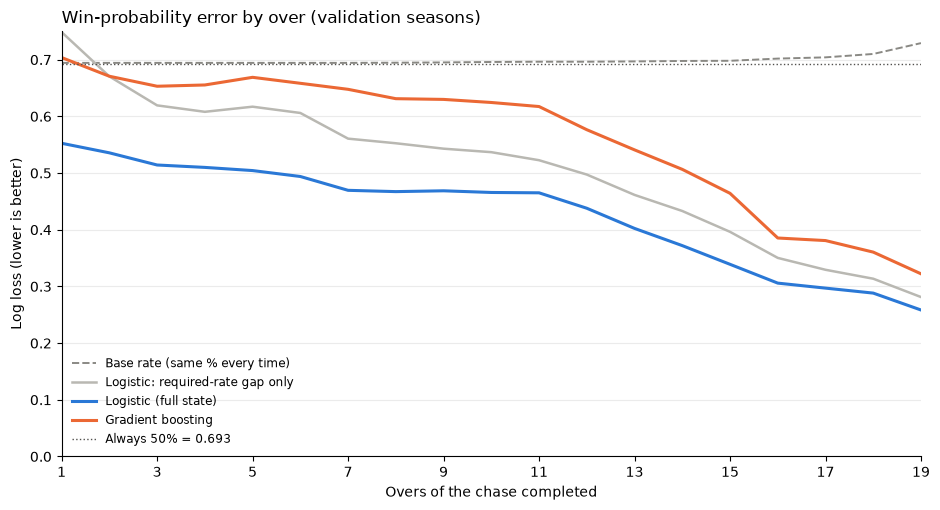

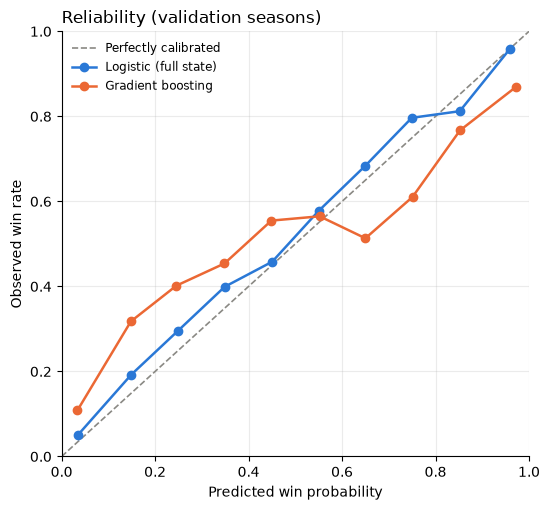

In [13]:
# ---- charts ----
GRAY, GRAY2, BLUE, ORANGE = "#8a8984", "#b9b8b2", "#2a78d6", "#eb6834"
style = {BASE: dict(color=GRAY, ls="--", lw=1.4), GAP: dict(color=GRAY2, ls="-", lw=1.8),
         FULL: dict(color=BLUE, ls="-", lw=2.2), GB: dict(color=ORANGE, ls="-", lw=2.2)}
fig, ax = plt.subplots(figsize=(9.5, 5.2))
for name, st in style.items():
    ax.plot(ll_by_over.index, ll_by_over[name], label=name, **st)
ax.axhline(np.log(2), color="#52514e", lw=1, ls=":", label="Always 50%% = %.3f" % np.log(2))
ax.set_ylim(0, 0.75)
ax.legend(frameon=False, loc="lower left", fontsize=8.5)
ax.set_xlabel("Overs of the chase completed")
ax.set_ylabel("Log loss (lower is better)")
ax.set_title("Win-probability error by over (validation seasons)", loc="left")
ax.set_xlim(1, 19)
ax.set_xticks(range(1, 20, 2))
ax.grid(axis="y", alpha=0.25)
for s in ("top", "right"):
    ax.spines[s].set_visible(False)
plt.tight_layout()
plt.savefig(REPORTS_DIR / "win_probability_logloss_by_over.png", dpi=150)
plt.show()

fig, ax = plt.subplots(figsize=(5.6, 5.2))
ax.plot([0, 1], [0, 1], color=GRAY, ls="--", lw=1.2, label="Perfectly calibrated")
for name, col in ((FULL, BLUE), (GB, ORANGE)):
    d = dev_preds[dev_preds["model"] == name]
    t, _ = calibration_table(d["p"].to_numpy(), d["y"].to_numpy())
    ax.plot(t["mean_predicted"], t["observed_win_rate"], marker="o", color=col, lw=1.8, label=name)
ax.set_xlabel("Predicted win probability")
ax.set_ylabel("Observed win rate")
ax.set_title("Reliability (validation seasons)", loc="left")
ax.legend(frameon=False, loc="upper left", fontsize=8.5)
ax.set_xlim(0, 1); ax.set_ylim(0, 1)
ax.grid(alpha=0.25)
for s in ("top", "right"):
    ax.spines[s].set_visible(False)
plt.tight_layout()
plt.savefig(REPORTS_DIR / "win_probability_reliability.png", dpi=150)
plt.show()

## 7. Sanity checks with hypothetical states
A win-probability model should follow cricket common sense: more runs needed -> lower probability; more wickets lost ->
lower probability; needing 1 run with wickets in hand -> almost certain. These use the champion fitted on development data
(not the holdout).

In [14]:
def even_path(total, k, wickets):
    # cumulative runs / wickets after each completed over, spread evenly (hypothetical state)
    runs = [int(round(total * (i + 1) / k)) for i in range(k)]
    wk = [int(round(wickets * (i + 1) / k)) for i in range(k)]
    return runs, wk


def context_now(venue_name, league_window=60, chase_window=100, venue_shrink=5.0):
    league = matches["final_score"].to_numpy()[-league_window:].mean()          # matches sorted by date
    sub = matches[matches["venue"] == standardize_venue(venue_name)]
    return dict(league_recent=league, venue_effect=sub["excess"].sum() / (len(sub) + venue_shrink),
                venue_n=len(sub), chase_rate_recent=matches["chase_won"].to_numpy()[-chase_window:].mean())


def state_row(target, cum_runs, cum_wickets, venue):
    k = len(cum_runs)
    assert 1 <= k <= 19 and len(cum_wickets) == k
    states = {i + 1: (cum_runs[i], cum_wickets[i], 0) for i in range(k)}
    row = chase_features(states, k, target)
    row.update(context_now(venue))
    return add_derived(pd.DataFrame([row]))


sanity_model = CHAMPION_CLS().fit(dev)
VENUE = matches["venue"].value_counts().index[0]
cases = [
    ("Par chase: over 10, 80/2, target 180", 180, *even_path(80, 10, 2)),
    ("Behind the rate: over 10, 60/4, target 180", 180, *even_path(60, 10, 4)),
    ("Ahead of the rate: over 10, 105/1, target 180", 180, *even_path(105, 10, 1)),
    ("Wickets in hand matter: over 15, 120/2, target 180", 180, *even_path(120, 15, 2)),
    ("... same score, 7 down: over 15, 120/7, target 180", 180, *even_path(120, 15, 7)),
    ("Last over, 6 needed, 5 down: over 19, 150/5, target 156", 156, *even_path(150, 19, 5)),
    ("Last over, 25 needed, 8 down: over 19, 135/8, target 160", 160, *even_path(135, 19, 8)),
    ("Almost won: over 18, 160/2, target 164", 164, *even_path(160, 18, 2)),
]
rows = []
for label, target, cr, cw in cases:
    rows.append({"state": label, "win_probability": float(sanity_model.predict_proba1(state_row(target, cr, cw, VENUE))[0])})
print("Champion:", champion, "| venue used for context:", VENUE)
display(pd.DataFrame(rows).set_index("state").round(3))

Champion: Logistic (full state) | venue used for context: Wankhede Stadium


,win_probability
state,
"Par chase: over 10, 80/2, target 180",0.626
"Behind the rate: over 10, 60/4, target 180",0.123
"Ahead of the rate: over 10, 105/1, target 180",0.932
"Wickets in hand matter: over 15, 120/2, target 180",0.618
"... same score, 7 down: over 15, 120/7, target 180",0.095
"Last over, 6 needed, 5 down: over 19, 150/5, target 156",0.962
"Last over, 25 needed, 8 down: over 19, 135/8, target 160",0.008
"Almost won: over 18, 160/2, target 164",0.998


## 8. Final holdout (2026) - evaluated once
Everything below is computed a single time. Do not re-run it with changed settings to chase a better number.
The holdout is one season, so the sample is small: read the confidence intervals.

In [15]:
print("Champion chosen on validation folds only:", champion)
print("Holdout matches:", holdout["match_id"].nunique(), "(small sample - read the CIs)")

if len(holdout):
    final_models = [M().fit(dev) for M in MODELS]
    hp = pd.concat([score_rows(holdout, m.predict_proba1(holdout)).assign(model=m.name) for m in final_models],
                   ignore_index=True)

    ll_h = hp.pivot_table(index="over", columns="model", values="loss", aggfunc="mean")
    print("\nHoldout log loss by over (2026):")
    display(ll_h.loc[[o for o in CHECKPOINTS if o in ll_h.index]].round(3))
    ll_h.to_csv(REPORTS_DIR / "win_probability_holdout_logloss.csv")

    acc_h = hp.pivot_table(index="over", columns="model", values="correct", aggfunc="mean")
    print("Holdout accuracy %:")
    display((100 * acc_h.loc[[o for o in CHECKPOINTS if o in acc_h.index]]).round(1))

    print("Mean log loss / Brier over overs 1-19:")
    print(hp.groupby("model")[["loss", "brier"]].mean().sort_values("loss").round(4).to_string())

    print("\nBootstrap comparisons on the holdout:")
    holdout_compare = compare(hp)
    show_compare(holdout_compare)
    holdout_compare.to_csv(REPORTS_DIR / "win_probability_holdout_bootstrap.csv", index=False)

    d = hp[hp["model"] == champion]
    t, ece = calibration_table(d["p"].to_numpy(), d["y"].to_numpy())
    print("\nHoldout calibration of the champion (%s): ECE = %.3f" % (champion, ece))
    display(t.round(3))
else:
    print("No 2026 matches in the data - holdout skipped.")

ll_by_over.round(4).to_csv(REPORTS_DIR / "win_probability_validation_logloss_by_over.csv")
dev_compare.to_csv(REPORTS_DIR / "win_probability_validation_bootstrap.csv", index=False)

Champion chosen on validation folds only: Logistic (full state)
Holdout matches: 70 (small sample - read the CIs)

Holdout log loss by over (2026):


model,Base rate (same % every time),Gradient boosting,Logistic (full state),Logistic: required-rate gap only
over,,,,
1,0.674,0.693,0.612,0.801
3,0.674,0.602,0.554,0.617
6,0.674,0.415,0.371,0.433
10,0.675,0.409,0.326,0.396
15,0.674,0.263,0.231,0.289
18,0.678,0.158,0.165,0.229


Holdout accuracy %:


model,Base rate (same % every time),Gradient boosting,Logistic (full state),Logistic: required-rate gap only
over,,,,
1,64.3,71.4,68.6,67.1
3,64.3,71.4,68.6,72.9
6,64.3,77.1,85.7,81.4
10,63.8,79.7,88.4,85.5
15,64.6,87.7,90.8,87.7
18,62.0,92.0,96.0,90.0


Mean log loss / Brier over overs 1-19:
                                    loss   brier
model                                           
Logistic (full state)             0.3491  0.1119
Gradient boosting                 0.3967  0.1273
Logistic: required-rate gap only  0.4192  0.1326
Base rate (same % every time)     0.6752  0.2410

Bootstrap comparisons on the holdout:

Logistic: required-rate gap only  vs  Base rate (same % every time)   (gain = reference log loss - challenger log loss; 95% match-bootstrap CI)


,n_matches,gain,ci_lo,ci_hi,verdict
over,,,,,
1,70,-0.127,-0.382,0.083,noise
3,70,0.057,-0.110,0.206,noise
6,70,0.242,0.131,0.335,challenger better
10,69,0.279,0.190,0.355,challenger better
15,65,0.385,0.291,0.465,challenger better
18,50,0.449,0.308,0.559,challenger better
ALL,70,0.262,0.174,0.337,challenger better


... (2 outputs left out)


Gradient boosting  vs  Logistic (full state)   (gain = reference log loss - challenger log loss; 95% match-bootstrap CI)


,n_matches,gain,ci_lo,ci_hi,verdict
over,,,,,
1,70,-0.081,-0.245,0.071,noise
3,70,-0.048,-0.177,0.075,noise
6,70,-0.044,-0.150,0.056,noise
10,69,-0.084,-0.201,0.030,noise
15,65,-0.031,-0.144,0.072,noise
18,50,0.007,-0.043,0.055,noise
ALL,70,-0.047,-0.144,0.045,noise



Holdout calibration of the champion (Logistic (full state)): ECE = 0.130


,n,mean_predicted,observed_win_rate
bin,,,
"(-0.001, 0.1]",251,0.031,0.028
"(0.1, 0.2]",89,0.145,0.191
"(0.2, 0.3]",84,0.252,0.405
"(0.3, 0.4]",72,0.354,0.653
"(0.4, 0.5]",94,0.445,0.702
"(0.5, 0.6]",91,0.546,0.846
"(0.6, 0.7]",87,0.646,0.885
"(0.7, 0.8]",96,0.754,0.958
"(0.8, 0.9]",142,0.856,0.993


## 9. See it on real matches
The probability path of real 2026 chases: the match with the **biggest upset** (the model was most confident in the wrong
side from over 10 on) and the one with the **biggest swing**.


=== biggest upset ===
Eden Gardens | Lucknow Super Giants chasing 182 | 2026-04-09 | RESULT: chasing team WON


,runs,wickets,runs_needed,rrr,p_chase_wins
over,,,,,
1,6,0,176.0,9.26,0.56
3,31,0,151.0,8.88,0.73
6,56,2,126.0,9.00,0.57
10,85,3,97.0,9.70,0.54
15,127,6,55.0,11.00,0.31
18,152,7,30.0,15.00,0.20



=== biggest swing ===
Arun Jaitley Stadium | Punjab Kings chasing 265 | 2026-04-25 | RESULT: chasing team WON


,runs,wickets,runs_needed,rrr,p_chase_wins
over,,,,,
1,15,0,250.0,13.16,0.10
3,56,0,209.0,12.29,0.28
6,116,0,149.0,10.64,0.71
10,147,3,118.0,11.80,0.38
15,203,4,62.0,12.40,0.55
18,252,4,13.0,6.50,0.99


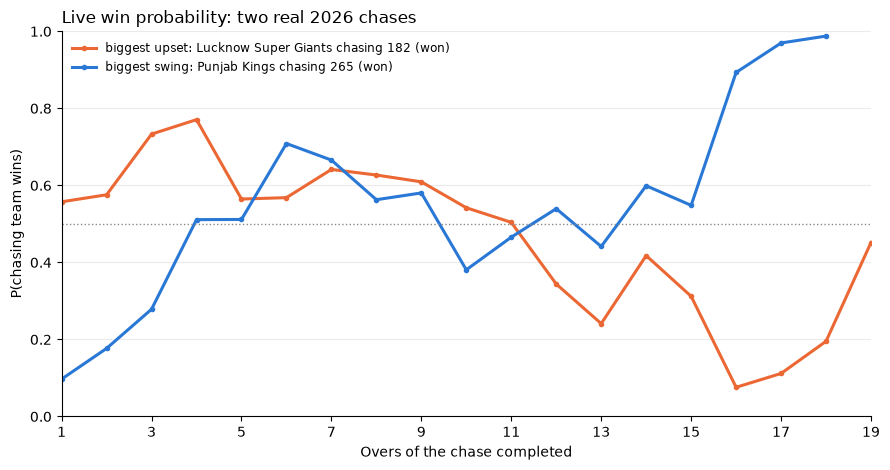

In [16]:
champ_model = [m for m in final_models if m.name == champion][0]
hc = holdout.assign(p=champ_model.predict_proba1(holdout))
info = matches.set_index("match_id")


def show_chase(match_id, overs=(1, 3, 6, 10, 15, 18)):
    g = hc[(hc["match_id"] == match_id) & (hc["over"].isin(overs))]
    r = info.loc[match_id]
    print("%s | %s chasing %d | %s | RESULT: chasing team %s" % (
        r["venue"], r["team2"], r["target"], r["date"].date(), "WON" if r["chase_won"] else "LOST"))
    display(g[["over", "runs", "wickets", "runs_needed", "rrr", "p"]].rename(columns={"p": "p_chase_wins"})
            .set_index("over").round(2))


late = hc[hc["over"] >= 10]
wrong_conf = late.assign(conf_wrong=np.where(late["y"] == 1, 1 - late["p"], late["p"])).groupby("match_id")["conf_wrong"].max()
swing = hc.groupby("match_id")["p"].agg(lambda s: s.max() - s.min())
picks = {"biggest upset": wrong_conf.idxmax(), "biggest swing": swing.idxmax()}
for label, mid_id in picks.items():
    print("\n=== %s ===" % label)
    show_chase(mid_id)

fig, ax = plt.subplots(figsize=(9, 4.8))
for (label, mid_id), col in zip(picks.items(), (ORANGE, BLUE)):
    g = hc[hc["match_id"] == mid_id].sort_values("over")
    r = info.loc[mid_id]
    ax.plot(g["over"], g["p"], color=col, lw=2.2, marker="o", ms=3,
            label="%s: %s chasing %d (%s)" % (label, r["team2"], r["target"], "won" if r["chase_won"] else "lost"))
ax.axhline(0.5, color=GRAY, ls=":", lw=1)
ax.set_ylim(0, 1); ax.set_xlim(1, 19)
ax.set_xticks(range(1, 20, 2))
ax.set_xlabel("Overs of the chase completed")
ax.set_ylabel("P(chasing team wins)")
ax.set_title("Live win probability: two real 2026 chases", loc="left")
ax.legend(frameon=False, loc="upper left", fontsize=8.5)
ax.grid(axis="y", alpha=0.25)
for s in ("top", "right"):
    ax.spines[s].set_visible(False)
plt.tight_layout()
plt.savefig(REPORTS_DIR / "win_probability_example_matches.png", dpi=150)
plt.show()

## 10. Use it: predict a live chase
Pass the target and the **cumulative** runs and wickets after each completed over, plus the venue.
After the holdout was evaluated, the final model is trained on **all** data.

In [17]:
win_model = CHAMPION_CLS().fit(snap)


def predict_win_prob(target, cum_runs, cum_wickets, venue):
    return float(win_model.predict_proba1(state_row(target, cum_runs, cum_wickets, venue))[0])


# Example: chasing 186; after 12 overs 98/3 (runs per over below, wickets cumulative)
runs_by_over = [6, 14, 25, 33, 41, 55, 63, 72, 80, 88, 93, 98]
wkts_by_over = [0, 0, 0, 1, 1, 1, 2, 2, 2, 3, 3, 3]
p = predict_win_prob(186, runs_by_over, wkts_by_over, venue=VENUE)
print("%s | chasing 186, 98/3 after 12 overs -> P(chasing team wins) = %.0f%%" % (VENUE, 100 * p))

# the whole curve for the same chase
curve = [predict_win_prob(186, runs_by_over[:k], wkts_by_over[:k], VENUE) for k in range(1, len(runs_by_over) + 1)]
print("Win probability after each over:", [round(c, 2) for c in curve])

Wankhede Stadium | chasing 186, 98/3 after 12 overs -> P(chasing team wins) = 59%
Win probability after each over: [0.64, 0.67, 0.73, 0.64, 0.66, 0.75, 0.67, 0.71, 0.74, 0.67, 0.63, 0.59]


## Export for the dashboard
Writes `nb04.json` into `dashboard/public/data/` (override with the `IPL_DASHBOARD_DATA` environment variable). The React dashboard reads these files.
This cell only reads results that are already in memory, so run it **after** the cells above.

In [18]:
# ===== Dashboard export =====================================================================
# Writes JSON files that the React dashboard reads. Safe to re-run; it only writes files.
import json, datetime

DASH_DIR = Path(os.environ.get("IPL_DASHBOARD_DATA", PROJECT_ROOT / "dashboard" / "public" / "data"))
DASH_DIR.mkdir(parents=True, exist_ok=True)


def _clean(x):
    if isinstance(x, dict):
        return {str(k): _clean(v) for k, v in x.items()}
    if isinstance(x, (list, tuple)):
        return [_clean(v) for v in x]
    if isinstance(x, pd.DataFrame):
        return _clean(x.reset_index().to_dict("records"))
    if isinstance(x, pd.Series):
        return _clean(x.to_dict())
    if isinstance(x, np.ndarray):
        return _clean(x.tolist())
    if isinstance(x, (bool, np.bool_)):
        return bool(x)
    if isinstance(x, (int, np.integer)):
        return int(x)
    if isinstance(x, (float, np.floating)):
        return round(float(x), 5) if np.isfinite(x) else None
    if isinstance(x, (pd.Timestamp, datetime.date)):
        return str(x)[:10]
    if x is None or isinstance(x, str):
        return x
    return str(x)


def tbl(df, scale=1.0):
    # pivot-style table -> {"index": [...], "columns": [...], "data": [[...]]}
    d = df.astype(float) * scale
    return {"index": _clean(list(d.index)), "columns": [str(c) for c in d.columns], "data": _clean(d.values.tolist())}


def recs(df):
    d = df.copy()
    for c in d.columns:
        if str(d[c].dtype).startswith("category") or d[c].dtype == object:
            d[c] = d[c].astype(str)
    return _clean(d.reset_index(drop=True).to_dict("records"))


def dash_save(name, payload):
    meta = {"notebook": name, "generated": datetime.datetime.now().isoformat(timespec="seconds"),
            "matches": int(len(matches)), "first_season": int(matches["season"].min()), "last_season": int(matches["season"].max())}
    path = DASH_DIR / (name + ".json")
    path.write_text(json.dumps(_clean({"meta": meta, **payload}), separators=(",", ":")), encoding="utf-8")
    print("wrote %s (%.0f KB)" % (path, path.stat().st_size / 1024))

cal_v = {}
for name in (FULL, GB):
    d_ = dev_preds[dev_preds["model"] == name]
    t_, e_ = calibration_table(d_["p"].to_numpy(), d_["y"].to_numpy())
    cal_v[name] = {"ece": float(e_), "bins": recs(t_.reset_index(drop=True))}
payload = {
    "champion": str(champion),
    "logloss_by_over": tbl(ll_by_over), "accuracy_by_over": tbl(acc_by_over, 100.0), "auc_by_over": tbl(auc),
    "compare_validation": recs(dev_compare), "calibration_validation": cal_v,
}
if "ll_h" in globals():
    d_ = hp[hp["model"] == champion]
    t_, e_ = calibration_table(d_["p"].to_numpy(), d_["y"].to_numpy())
    payload.update(logloss_holdout=tbl(ll_h), accuracy_holdout=tbl(acc_h, 100.0), compare_holdout=recs(holdout_compare),
                   calibration_holdout={"ece": float(e_), "bins": recs(t_.reset_index(drop=True))},
                   holdout_chase_win_rate=float(hold_y_rate) if "hold_y_rate" in globals() else float(holdout.groupby("match_id")["y"].first().mean()))
dash_save("nb04", payload)

wrote c:\Users\amitb\Desktop\ME\Projects\Data_Analysis_Practice\cricket-analytics-lab\dashboard\public\data\nb04.json (14 KB)


In [19]:
# ===== Per-match export for the dashboard (paste as a NEW LAST CELL) ========================
import json, datetime

DASH_DIR = Path(os.environ.get("IPL_DASHBOARD_DATA", PROJECT_ROOT / "dashboard" / "public" / "data"))
DASH_DIR.mkdir(parents=True, exist_ok=True)
OVERS = list(range(1, 20))                                   # overs 1..19 (the over-20 state is the final score)


def pack_by_match(df, col, nd=3):
    # one list of 19 numbers per match (index 0 = over 1); None where that over has no row
    piv = df.pivot_table(index="match_id", columns="over", values=col, aggfunc="first").reindex(columns=OVERS)
    return {str(mid): [None if pd.isna(v) else round(float(v), nd) for v in row] for mid, row in zip(piv.index, piv.values)}


def merge_save(file, section, payload):
    # predictions.json is shared by notebooks 03, 04 and 06: each one only replaces its own section
    path = DASH_DIR / (file + ".json")
    cur = {}
    if path.exists():
        try:
            cur = json.loads(path.read_text(encoding="utf-8"))
        except Exception:
            cur = {}
    meta = cur.get("meta", {})
    meta.update({"generated": datetime.datetime.now().isoformat(timespec="seconds"), "matches": int(len(matches)),
                 "first_season": int(matches["season"].min()), "last_season": int(matches["season"].max())})
    cur["meta"] = meta
    cur[section] = payload
    meta["sections"] = sorted(k for k in cur if k != "meta")
    path.write_text(json.dumps(cur, separators=(",", ":")), encoding="utf-8")
    print("wrote %s section '%s' (file now %.0f KB)" % (path, section, path.stat().st_size / 1024))

# Out-of-sample champion P(chasing side wins) at every over, for every validation and holdout match.
_v = dev_preds[dev_preds["model"] == champion][["match_id", "over", "p"]]
_parts, _split = [_v], {str(m): "val" for m in _v["match_id"].unique()}
if "hp" in globals():
    _h = hp[hp["model"] == champion][["match_id", "over", "p"]]
    _parts.append(_h)
    _split.update({str(m): "hold" for m in _h["match_id"].unique()})
_pk = pack_by_match(pd.concat(_parts, ignore_index=True), "p", nd=4)
merge_save("predictions", "nb04", {
    "model": str(champion), "overs": OVERS,
    "matches": {m: {"split": s, "p": _pk[m]} for m, s in _split.items()},
})

wrote c:\Users\amitb\Desktop\ME\Projects\Data_Analysis_Practice\cricket-analytics-lab\dashboard\public\data\predictions.json section 'nb04' (file now 225 KB)
